# 09 TESTES DE HIPÓTESE SOBRE VARIABILIDADE INTERANUAL ($\chi^2$), DESPRENDIMENTO DA PINE ISLAND (2020), COERÊNCIA ENSO E PERDA MULTI-SENSOR DO TRONCO OESTE DA THWAITES EM 2024

Este caderno encerra a cadeia científica avaliando quatro hipóteses dinâmicas e climáticas sobre a variabilidade temporal (2019–2025) no Mar de Amundsen:

1. **Hipótese 1 — Variabilidade interanual do derretimento basal (`run_annual_mb_v2.py` e teste $Q/\chi^2$ de Cochran, 1954):**
   - *Problema metodológico corrigido:* Séries trimestrais baseadas em derivadas por janela móvel de 5 estações compartilham observações entre trimestres adjacentes, induzindo oscilações autocorrelacionadas artificiais (falsos máximos e mínimos).
   - *Solução:* Construímos estimativas anuais estritamente disjuntas em que cada ano ($2019, \dots, 2025$) utiliza exclusivamente as 4 estações do próprio ano. O teste de homogeneidade $Q = \sum_{t=1}^7 (m_{b,t} - \hat{\mu}_w)^2 / \sigma_t^2 \sim \chi^2_6$ revela que **apenas a Thwaites Oriental (TEIS) apresenta variabilidade interanual fortemente significativa acima do erro estatístico** ($\chi^2 = 29{,}3$, $p = 5\times 10^{-5}$), com sinal marginal na Cosgrove ($p = 0{,}04$), enquanto Pine Island ($p = 0{,}98$), Crosson ($p = 0{,}90$) e Dotson ($p = 0{,}65$) são estatisticamente compatíveis com derretimento médio constante dentro da precisão atual.

2. **Hipótese 2 — Resposta do derretimento basal ao grande desprendimento (*calving*) da Pine Island em fevereiro de 2020 (`run_calving_response_test.py`):**
   - *Evento:* As frentes datadas Sentinel-1/IceLines registram um recuo abrupto de $8{,}8\text{ km}$ da frente da Pine Island entre meados de 2019 e meados de 2020.
   - *Desenho quase-experimental (Diferença-em-Diferenças com controles espaciais e inter-plataformas):* Comparando a janela independente PRÉ-desprendimento (`DJF 2019` a `DJF 2020`, excluindo a transição `MAM 2020`) com a janela independente PÓS-desprendimento (`JJA 2020` a `SON 2021`), o derretimento basal na PIG não sofre queda: $\Delta m_b = +3{,}8 \pm 16{,}1\text{ m/ano}$ na plataforma inteira, $+5{,}8 \pm 20{,}0\text{ m/ano}$ longe da frente ($> 10\text{ km}$) e $+8{,}1 \pm 5{,}1\text{ m/ano}$ perto da frente ($z = 1{,}6$). A única variação próxima de $2\sigma$ ocorre na TEIS ($+13{,}8 \pm 5{,}9\text{ m/ano}$, $z = 2{,}4$), que **não** sofreu desprendimento.

3. **Hipótese 3 — Acoplamento inter-plataformas e coerência com o El Niño–Oscilação Sul (ENSO/ONI; Meng et al., 2025; `run_coherence_test_ase.py`):**
   - *Teste rigoroso:* Submetendo as anomalias destendenciadas e suavizadas em 4 trimestres ao teste de $2.000$ séries substitutas de fase de Fourier aleatória (Theiler et al., 1992; Ebisuzaki, 1997) com graus de liberdade efetivos $N_{\text{ef}} \in [3{,}1;\; 7{,}3]$ (Bretherton et al., 1999), **0 de 10 pares de plataformas** exibe coerência mútua significativa com o firn GEMB. Contra o índice ONI em defasagens de $0\text{ a }4$ trimestres ($25$ testes), apenas $1$ teste atinge $p < 0{,}05$ (PIG em lag 4, $p = 0{,}048$), exatamente a taxa de $4\%$ esperada pelo acaso sob $H_0$! Mais importante: a contribuição direta da variação do conteúdo de ar do firn ($+9{,}34\,d\text{FAC}/dt$) possui variância de $0{,}1\text{ a }2{,}1\times$ a variância das anomalias de $m_b$ e correlaciona-se fortemente com elas na TEIS ($r = -0{,}71$) e na Dotson ($r = -0{,}78$), demonstrando que parte substancial da aparente variabilidade interanual vem do modelo de firn e não de forçante oceânica.

4. **Quantificação Multi-Sensor da Evacuação do Tronco Oeste da Thwaites (TWGT) e Mélange em 2024 (ICESat-2 + Sentinel-1 + MODIS; Miles et al., 2020; Crawford et al., 2024):**
   - Em $215$ blocos fixos de $2\text{ km}$ sobre o tronco oeste e o mélange da Thwaites ($28$ épocas sazonais), a fração de cobertura de gelo espesso (borda livre aparente $\ge 10\text{ m}$) cai abruptamente de **$59{,}6\%$ para $44{,}1\%$** entre DJF 2023/24 e MAM 2024 ($-15{,}5 \pm 2{,}5\text{ pontos percentuais}$, $6{,}3\sigma$, $\Delta\text{BIC} = 32{,}8$, mesma data em $99{,}8\%$ das réplicas de jackknife), enquanto a espessura hidrostática efetiva cai de **$181\text{ m}$ para $142\text{ m}$** ($-39 \pm 7\text{ m}$, $5{,}4\sigma$), equivalendo a **$-29 \pm 5\text{ Gt}$** nos $803\text{ km}^2$ amostrados ($-58 \pm 11\text{ Gt}$ no domínio de $1.617\text{ km}^2$). O radar **Sentinel-1** (órbita 21, retroespalhamento HH) e imagens **MODIS** ($250\text{ m}$) datam a ruptura do gelo marinho preso (*landfast sea ice*) em 4 de fevereiro de 2024 e a dispersão do mélange entre **5 de fevereiro e 12 de março de 2024**, seguida de uma 2ª etapa na língua da TWGT a partir de SON 2024.

### Roteiro do caderno
| Seção | Hipótese | Ferramenta estatística (Caderno 00) | Aplicação em código |
|---|---|---|---|
| 1 | O derretimento varia entre anos? | teste $Q$ de Cochran (§2.7) + FDR entre plataformas (§2.3) | séries anuais disjuntas |
| 2 | A PIG respondeu ao desprendimento de 2020? | diferença pré/pós em janelas disjuntas, controles espaciais | $z$ por conjunto e diferença-em-diferenças |
| 3 | Há coerência com o ENSO? | $N_{\text{ef}}$ + substitutas de Fourier (§2.6) + FDR | pares de plataformas e índice ONI |
| 4 | O que aconteceu no tronco oeste da Thwaites em 2024? | $\Delta\text{BIC}$ degrau × reta (§2.8), jackknife | degrau, massa e zonas de mélange |
| 5 | Síntese geral do projeto | — | — |

In [1]:
# ── Configuração comum do caderno ─────────────────────────────────────────────
# Localiza a raiz do repositório (a pasta que contém o pacote `thwaites/`), torna o
# pacote importável mesmo sem `pip install -e .` e aponta DATA_DIR para as tabelas
# resumidas que alimentam todas as figuras. Basta executar o caderno de cima para baixo.
import sys
import json
from pathlib import Path

_candidatas = [Path.cwd(), *Path.cwd().parents]
REPO_ROOT = next((p for p in _candidatas if (p / "thwaites").is_dir()), None)
if REPO_ROOT is None:
    raise RuntimeError("Execute o caderno a partir de dentro do repositório (pasta com 'thwaites/').")
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
DATA_DIR = REPO_ROOT / "notebooks" / "dados_resumo"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "font.size": 9, "axes.titlesize": 9.5,
})
# Mensagens de log da biblioteca: só erros (os cadernos não chamam setup_logging()).
try:
    from loguru import logger as _logger
    import thwaites.logging as _tlog
    _logger.remove()
    _logger.add(sys.stderr, level="ERROR", format="{level}: {message}")
    _tlog._CONFIGURED = True
except ImportError:
    pass

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
CORES = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E",
         "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
print(f"Tabelas resumidas disponíveis em dados_resumo/: {len(list(DATA_DIR.glob('*')))}")

Tabelas resumidas disponíveis em dados_resumo/: 74


---
## 1. Hipótese 1 — Variabilidade Interanual do Derretimento Basal

As séries anuais usam janelas **disjuntas** (cada ano só com as suas 4 estações), condição para o teste $Q$ ser válido (Caderno 00 §2.7). O painel (b) da figura antecipa a Hipótese 2.

,media_ponderada,sigma_media,chi2,gl,p
unidade,,,,,
Pine_Island,8.8946,4.3991,1.1689,6,0.9784
Thwaites_TEIS,4.5568,1.0591,29.2928,6,0.0001
Thwaites_TWGT,42.3936,7.0503,3.5041,6,0.7434
Crosson,8.3257,1.7635,2.1764,6,0.9028
Dotson,6.5733,0.9713,4.2126,6,0.6479
Cosgrove,0.3776,0.3086,13.3629,6,0.0376


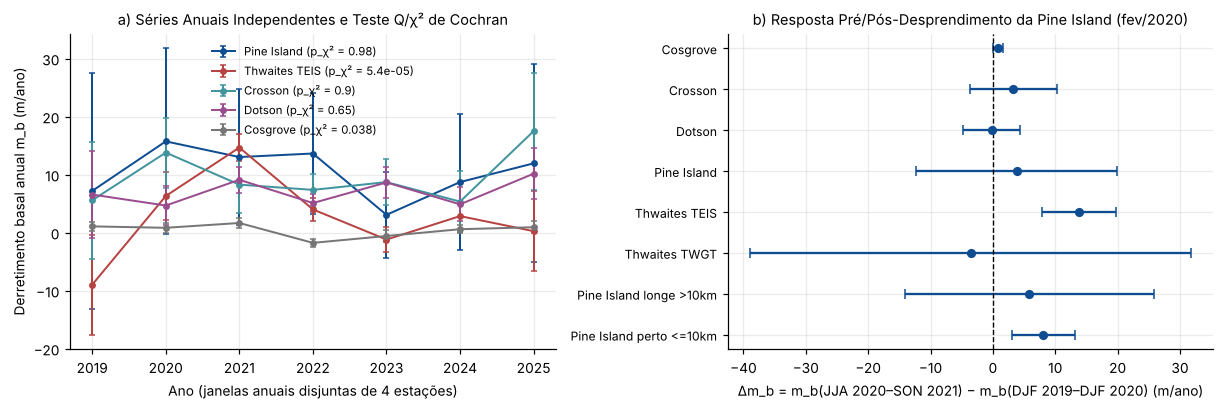

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

mb_anual = pd.read_csv(DATA_DIR / "serie_anual_independente_mb.csv")
chi2_tab = pd.read_csv(DATA_DIR / "teste_chi2_variabilidade_anual.csv")
calving_tab = pd.read_csv(DATA_DIR / "teste_calving_pig_2020.csv")
coer_pares = pd.read_csv(DATA_DIR / "coerencia_enso_pares_plataformas.csv")
coer_oni = pd.read_csv(DATA_DIR / "coerencia_firn_e_oni.csv")
ev2024_deg = json.loads((DATA_DIR / "evento_2024_tronco_thwaites_degrau.json").read_text(encoding="utf-8"))
ev2024_mas = json.loads((DATA_DIR / "evento_2024_tronco_thwaites_massa.json").read_text(encoding="utf-8"))
mel_zonas = pd.read_csv(DATA_DIR / "melange_mudanca_zonas.csv")

fig, ax = plt.subplots(1, 2, figsize=(11.2, 3.8))
colors = {"Pine_Island": "#0F4D92", "Thwaites_TEIS": "#B64342", "Crosson": "#42949E", "Dotson": "#9A4D8E", "Cosgrove": "#767676"}
for u, col in colors.items():
    sub = mb_anual[mb_anual["unidade"] == u].sort_values("ano")
    p_val = float(chi2_tab.loc[chi2_tab["unidade"] == u, "p"].iloc[0])
    ax[0].errorbar(sub["ano"], sub["mb_mpa"], yerr=sub["se_mpa"], fmt="o-", color=col, lw=1.3, ms=3.5, capsize=2,
                   label=f"{u.replace('_', ' ')} (p_χ² = {p_val:.2g})")
ax[0].set_xlabel("Ano (janelas anuais disjuntas de 4 estações)")
ax[0].set_ylabel("Derretimento basal anual m_b (m/ano)")
ax[0].set_title("a) Séries Anuais Independentes e Teste Q/χ² de Cochran")
ax[0].legend(frameon=False, fontsize=7.5)

y_c = np.arange(len(calving_tab))[::-1]
ax[1].errorbar(calving_tab["delta"], y_c, xerr=calving_tab["sigma_delta"], fmt="o", color="#0F4D92", lw=1.5, ms=5, capsize=3)
ax[1].axvline(0.0, color="k", ls="--", lw=0.9)
ax[1].set_yticks(y_c)
ax[1].set_yticklabels([c.replace("_", " ") for c in calving_tab["conjunto"]], fontsize=8)
ax[1].set_xlabel("Δm_b = m_b(JJA 2020–SON 2021) − m_b(DJF 2019–DJF 2020) (m/ano)")
ax[1].set_title("b) Resposta Pré/Pós-Desprendimento da Pine Island (fev/2020)")
plt.tight_layout()

chi2_tab.set_index("unidade").round(4)

**Aplicação: seis plataformas testadas ao mesmo tempo.** Com 6 testes, a chance de pelo menos um $p < 0{,}05$ por acaso é de ~26%. Corrigimos pela FDR de Benjamini–Hochberg:

In [3]:
from thwaites.stats import benjamini_hochberg_fdr

rej, p_adj = benjamini_hochberg_fdr(chi2_tab["p"].to_numpy(), alpha=0.05)
chi2_tab.assign(**{"Q / gl": chi2_tab["chi2"] / chi2_tab["gl"], "p ajustado (BH)": p_adj,
                   "Variabilidade real (FDR 5%)": rej}).set_index("unidade").round(4)

,media_ponderada,sigma_media,chi2,gl,p,Q / gl,p ajustado (BH),Variabilidade real (FDR 5%)
unidade,,,,,,,,
Pine_Island,8.8946,4.3991,1.1689,6,0.9784,0.1948,0.9784,False
Thwaites_TEIS,4.5568,1.0591,29.2928,6,0.0001,4.8821,0.0003,True
Thwaites_TWGT,42.3936,7.0503,3.5041,6,0.7434,0.5840,0.9784,False
Crosson,8.3257,1.7635,2.1764,6,0.9028,0.3627,0.9784,False
Dotson,6.5733,0.9713,4.2126,6,0.6479,0.7021,0.9784,False
Cosgrove,0.3776,0.3086,13.3629,6,0.0376,2.2271,0.1129,False


**Leitura do resultado.**
- A **TEIS** é a única plataforma com variabilidade interanual robusta ($Q/\text{gl} \approx 4{,}9$; continua significativa após a correção). A série anual tem um pico em 2021 (~15 m/ano) seguido de valores baixos em 2022–2025 (−1 a 4 m/ano), coerente com a mudança de regime da plataforma: o afinamento Lagrangiano nos blocos coerentes da TEIS passa de −6,6 m/ano em 2019–2021 para −2,3 m/ano em 2022–2025 (tabela da Seção 4).
- A **Cosgrove** ($p = 0{,}038$) **não sobrevive** à correção para 6 testes: é um sinal marginal que não deve ser interpretado isoladamente.
- **PIG, Crosson, Dotson e TWGT:** a dispersão entre anos cabe no erro ($Q/\text{gl} < 1$). Não se pode afirmar que o derretimento médio mudou entre anos com a precisão atual. Note que "não detectado" não significa "constante": os erros anuais da PIG são de ±4–15 m/ano.

---
## 2. Hipótese 2 — Resposta ao Desprendimento da Pine Island (Fevereiro de 2020)

**Desenho.** Comparar o derretimento na janela pré-evento (DJF 2019–DJF 2020) com a pós-evento (JJA 2020–SON 2021), excluindo o trimestre de transição, $z = \Delta m_b / \sqrt{\sigma_{\text{pré}}^2 + \sigma_{\text{pós}}^2}$. Plataformas que **não** sofreram desprendimento servem de controle: se elas mudam tanto quanto a PIG, a mudança não pode ser atribuída ao evento (raciocínio de diferença-em-diferenças).

In [4]:
cv = calving_tab.set_index("conjunto")
controles = ["Crosson", "Dotson", "Cosgrove"]
delta_ctrl = cv.loc[controles, "delta"].mean()
sig_ctrl = np.sqrt((cv.loc[controles, "sigma_delta"] ** 2).sum()) / len(controles)

linhas = []
for alvo in ["Pine_Island", "Pine_Island_perto_<=10km", "Pine_Island_longe_>10km"]:
    did = cv.loc[alvo, "delta"] - delta_ctrl
    s_did = np.hypot(cv.loc[alvo, "sigma_delta"], sig_ctrl)
    linhas.append({"Conjunto": alvo.replace("_", " "), "Δm_b alvo (m/ano)": cv.loc[alvo, "delta"],
                   "Δm_b médio dos controles (m/ano)": delta_ctrl, "Diferença-em-diferenças (m/ano)": did,
                   "σ (m/ano)": s_did, "z": did / s_did})
display(cv[["mb_antes", "sigma_antes", "mb_depois", "sigma_depois", "delta", "sigma_delta", "z"]].round(2))
pd.DataFrame(linhas).set_index("Conjunto").round(2)

,mb_antes,sigma_antes,mb_depois,sigma_depois,delta,sigma_delta,z
conjunto,,,,,,,
Cosgrove,1.25,0.70,2.10,0.41,0.85,0.82,1.05
Crosson,7.03,6.59,10.33,2.25,3.30,6.96,0.47
Dotson,9.49,4.32,9.28,1.44,-0.21,4.55,-0.05
Pine_Island,3.88,15.37,7.69,4.79,3.82,16.10,0.24
Thwaites_TEIS,-1.09,5.66,12.71,1.51,13.81,5.86,2.36
Thwaites_TWGT,39.67,34.45,36.08,8.07,-3.59,35.39,-0.10
Pine_Island_longe_>10km,10.26,19.32,16.11,5.15,5.85,20.00,0.29
Pine_Island_perto_<=10km,-6.26,4.47,1.83,2.38,8.10,5.06,1.60


,Δm_b alvo (m/ano),Δm_b médio dos controles (m/ano),Diferença-em-diferenças (m/ano),σ (m/ano),z
Conjunto,,,,,
Pine Island,3.82,1.31,2.51,16.34,0.15
Pine Island perto <=10km,8.10,1.31,6.78,5.78,1.17
Pine Island longe >10km,5.85,1.31,4.53,20.19,0.22


**Leitura do resultado.**
- Nenhum conjunto da Pine Island tem $|z| > 2$, nem na comparação direta nem após subtrair a variação média das plataformas de controle. O derretimento **não caiu** após o desprendimento. O máximo sugerido é um aumento perto da frente ($z \approx 1{,}6$), insuficiente para afirmação.
- A única variação próxima de $2\sigma$ ocorreu na **TEIS**, que não sofreu desprendimento. Isso mostra a amplitude da variabilidade regional "de fundo" e reforça que a resposta da PIG não se destaca dela.
- Limitação: com 5 estações antes do evento, os erros pré-evento são grandes (±15–19 m/ano na PIG). O teste tem baixo poder para efeitos menores que ~10 m/ano.

---
## 3. Hipótese 3 — Coerência entre Plataformas e com o ENSO

In [5]:
# Resumo da Coerência Inter-Plataformas (GEMB vs. IMAU-FDM) e Correlação com Firn (+9,34 dFAC/dt) e Índice ONI (ENSO)
print("=== RESUMO DA COERÊNCIA ENTRE OS 10 PARES DE PLATAFORMAS (2.000 SUBSTITUTAS DE FASE DE FOURIER) ===")
resumo_coer = coer_pares.groupby(["variante", "firn"]).agg(
    n_pares=("r", "size"),
    r_mediano=("r", "median"),
    pares_signif_p005=("p_substitutas", lambda s: int((s < 0.05).sum())),
    N_ef_mediano=("N_ef", "median"),
)
print(resumo_coer.round(3).to_string())

coer_oni.set_index("unidade").round(3)

=== RESUMO DA COERÊNCIA ENTRE OS 10 PARES DE PLATAFORMAS (2.000 SUBSTITUTAS DE FASE DE FOURIER) ===
                       n_pares  r_mediano  pares_signif_p005  N_ef_mediano
variante firn                                                             
A        GEMB               10     -0.044                  0         5.234
         IMAU_2019_23       10      0.050                  2         8.128
B        GEMB               10      0.145                  0         2.792
         IMAU_2019_23       10        NaN                  0           NaN


,r_mb_vs_firn,p_firn,var_firn_sobre_var_mb,r_ONI_lag0,p_ONI_lag0,r_ONI_lag1,p_ONI_lag1,r_ONI_lag2,p_ONI_lag2,r_ONI_lag3,p_ONI_lag3,r_ONI_lag4,p_ONI_lag4
unidade,,,,,,,,,,,,,
Pine_Island,-0.415,0.305,0.095,-0.163,0.794,-0.236,0.688,-0.372,0.504,-0.500,0.191,-0.684,0.048
Thwaites_TEIS,-0.710,0.044,0.207,-0.551,0.293,-0.485,0.397,-0.412,0.530,-0.245,0.751,-0.010,0.992
Crosson,-0.101,0.820,2.071,-0.338,0.462,-0.426,0.352,-0.437,0.324,-0.305,0.570,-0.127,0.833
Dotson,-0.781,0.016,1.365,-0.046,0.901,-0.368,0.384,-0.622,0.097,-0.712,0.075,-0.613,0.125
Cosgrove,0.432,0.444,1.416,0.209,0.818,0.444,0.608,0.669,0.384,0.814,0.174,0.890,0.071


In [6]:
# 25 testes contra o ONI (5 plataformas × 5 defasagens): quantos sobrevivem à FDR?
p_oni = coer_oni.melt(id_vars="unidade", value_vars=[f"p_ONI_lag{k}" for k in range(5)], var_name="lag", value_name="p")
p_oni["lag"] = p_oni["lag"].str.replace("p_ONI_lag", "").astype(int)
rej, p_adj = benjamini_hochberg_fdr(p_oni["p"].to_numpy(), alpha=0.05)
p_oni["p ajustado (BH)"] = p_adj
print(f"Testes com p < 0,05 (sem correção): {int((p_oni['p'] < 0.05).sum())} de {len(p_oni)} — esperado por acaso: {0.05 * len(p_oni):.2f}")
print(f"Testes significativos após FDR 5%: {int(rej.sum())}")
p_oni.sort_values("p").head(5).round(3).set_index(["unidade", "lag"])

Testes com p < 0,05 (sem correção): 1 de 25 — esperado por acaso: 1.25
Testes significativos após FDR 5%: 0


p  p ajustado (BH)
unidade     lag                        
Pine_Island 4    0.048            0.606
Cosgrove    4    0.071            0.606
Dotson      3    0.075            0.606
            2    0.097            0.606
            4    0.125            0.625

**Leitura do resultado.**
- **Entre plataformas:** com o firn GEMB, nenhum dos 10 pares tem coerência significativa, e a correlação mediana é ~0. Os 2 pares significativos na variante IMAU (período mais curto, 2019–2023) não se repetem com GEMB nem na variante B, o que indica sensibilidade ao modelo de firn e não sinal oceânico comum.
- **Com o ENSO:** 1 em 25 testes tem $p < 0{,}05$ (PIG, lag 4), contra ~1,25 esperado por puro acaso, e **nenhum** sobrevive à FDR. O Caderno 00 §2.6 mostrou ainda que, com $N \approx 21$, esses testes já são ligeiramente liberais. **Não há evidência de acoplamento ENSO** nestas séries.
- **O que explica então a variabilidade?** A anomalia do firn ($+9{,}34\,d\text{FAC}/dt$) correlaciona-se fortemente com as anomalias de $m_b$ na TEIS ($r = -0{,}71$) e na Dotson ($r = -0{,}78$), e na Crosson tem variância 2× maior que a do próprio $m_b$. Parte importante da "variabilidade interanual" de derretimento é **variabilidade do modelo de firn** propagada pela conversão hidrostática. Isso deve ser considerado antes de atribuir oscilações a forçantes oceânicas (crítica *(v)* a Meng et al., 2025, no Caderno 06).

---
## 4. Hipótese 4 — Evento de 2024 no Tronco Oeste da Thwaites e no Mélange

In [7]:
# Síntese Completa do Evento de 2024 no Tronco Oeste da Thwaites e Controle na Plataforma Oriental (TEIS)
df_ev = pd.DataFrame(ev2024_deg["teste"])
cols_ev = ["populacao", "dominio", "variavel", "epocas", "data_degrau", "antes", "depois", "degrau", "sigma_jk", "z", "replicas_mesma_data", "dBIC_reta_menos_degrau", "veredito"]
df_ev[[c for c in cols_ev if c in df_ev.columns]].set_index(["populacao", "dominio", "variavel"]).round(3)

epocas  data_degrau    antes   depois  degrau  sigma_jk      z  replicas_mesma_data  dBIC_reta_menos_degrau                            veredito
populacao dominio          variavel                                                                                                                                                 
com QC    tronco e mélange gelo          28     2024.167    0.596    0.441  -0.155     0.025 -6.316                0.998                  32.795                   degrau confirmado
                           H             28     2024.167  181.375  142.392 -38.983     7.221 -5.398                1.000                  19.199                   degrau confirmado
          TEIS coerente    gelo          27     2021.917    0.998    1.000   0.002     0.002  0.946                0.995                  -1.677                       não detectado
                           H             27     2021.667  319.476  302.717 -16.760     1.721 -9.737                0.995                 -12.332  queda real, forma não estabelecida
sem QC    tronco e mélange gelo          28     2024.167    0.592    0.458  -0.133     0.023 -5.878                1.000                  25.084                   degrau confirmado
                           H             28     2024.167  181.101  141.957 -39.145     7.346 -5.329                1.000                  17.466  queda real, forma não estabelecida

,Valor
Degrau de espessura H (m),-39.0 ± 7.2
Área dos blocos amostrados (km²),803
Massa perdida nos blocos (Gt),-28.7 ± 5.3
Área do domínio (km²),1617
Massa perdida no domínio (Gt),-57.8 ± 10.7
Queda do retroespalhamento Sentinel-1 (blocos / domínio / fora),-0.176 / -0.170 / -0.163
Blocos com perda completa / com perda > 10 pts / com ganho,8 / 97 / 48 (de 215)
Fração da queda explicada por perda completa de blocos,20%
Controle TEIS: afinamento 2019–21 / 2022–25 (m/ano),-6.6 / -2.3


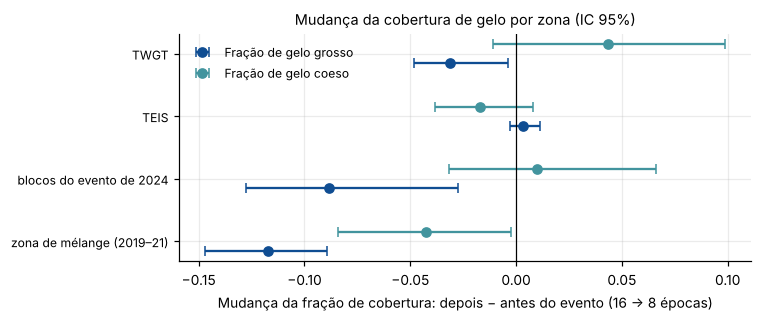

In [8]:
mas = ev2024_mas["A_massa_degrau"]
d7 = ev2024_deg["D7"]
display(pd.Series({
    "Degrau de espessura H (m)": f"{mas['degrau_m']:.1f} ± {mas['sigma_m']:.1f}",
    "Área dos blocos amostrados (km²)": f"{mas['area_blocos_km2']:.0f}",
    "Massa perdida nos blocos (Gt)": f"{mas['massa_blocos_Gt']:.1f} ± {mas['sigma_blocos_Gt']:.1f}",
    "Área do domínio (km²)": f"{mas['area_dominio_km2']:.0f}",
    "Massa perdida no domínio (Gt)": f"{mas['massa_dominio_Gt']:.1f} ± {mas['sigma_dominio_Gt']:.1f}",
    "Queda do retroespalhamento Sentinel-1 (blocos / domínio / fora)": f"{mas['s1_queda_blocos']:.3f} / {mas['s1_queda_dominio']:.3f} / {mas['s1_queda_fora_dos_blocos']:.3f}",
    "Blocos com perda completa / com perda > 10 pts / com ganho": f"{d7['perda_completa_blocos']} / {d7['blocos_com_perda_maior_10pts']} / {d7['blocos_com_ganho']} (de {d7['blocos']})",
    "Fração da queda explicada por perda completa de blocos": f"{100 * d7['fracao_da_queda_perda_completa']:.0f}%",
    "Controle TEIS: afinamento 2019–21 / 2022–25 (m/ano)": f"{ev2024_mas['B_incerteza_TEIS']['tendencia_2019_2021']:.1f} / {ev2024_mas['B_incerteza_TEIS']['tendencia_2022_2025']:.1f}",
}, name="Valor").to_frame())

zonas = mel_zonas[(mel_zonas["estacao"] == "todas")]
fig, ax = plt.subplots(figsize=(7.0, 3.0))
for j, (var, cor) in enumerate([("grosso", "#0F4D92"), ("coeso", "#42949E")]):
    g = zonas[zonas["variavel"] == var].reset_index(drop=True)
    y = np.arange(len(g)) + (0.15 if j else -0.15)
    ax.errorbar(g["dif"], y, xerr=[g["dif"] - g["lo"], g["hi"] - g["dif"]], fmt="o", color=cor, capsize=3,
                label=f"Fração de gelo {var}")
ax.set_yticks(np.arange(len(g))); ax.set_yticklabels(g["zona"], fontsize=8)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("Mudança da fração de cobertura: depois − antes do evento (16 → 8 épocas)"); ax.set_title("Mudança da cobertura de gelo por zona (IC 95%)")
ax.legend(frameon=False, fontsize=8); plt.tight_layout()

**Leitura do resultado.**
- **Degrau confirmado no tronco e mélange:** a fração de gelo espesso cai 15,5 pontos e a espessura efetiva 39 m no mesmo trimestre (início de 2024), com $\Delta\text{BIC} = 33$ e 19 a favor do degrau, $|z| > 5$, a mesma data em ~100% das réplicas jackknife e o mesmo degrau em todas as estações (D1–D5). Sem o QC dos blocos, o degrau na fração de gelo se mantém. Para $H$, o tamanho é o mesmo (−39 m) e o $\Delta\text{BIC}$ ainda favorece o degrau, mas nem todos os critérios de robustez passam, e o veredito cai para "queda real, forma não estabelecida". Pelo Caderno 00 §2.8, essa combinação descarta uma tendência gradual mal amostrada.
- **Massa:** ~29 ± 5 Gt nos 803 km² amostrados e ~58 ± 11 Gt extrapolados ao domínio de 1.617 km². A queda do retroespalhamento Sentinel-1 é semelhante dentro e fora dos blocos (−0,16 a −0,18), o que apoia a extrapolação.
- **Natureza do evento:** só 8 de 215 blocos perderam todo o gelo; quase metade perdeu mais de 10 pontos. A queda é **distribuída** (evacuação do mélange e afinamento difuso), não o desaparecimento de alguns poucos blocos.
- **Controle:** na TEIS coerente, a cobertura de gelo não muda. A espessura cai, mas como tendência (o modelo de degrau não é preferido; veredito "forma não estabelecida"). O evento de 2024 é **localizado** no tronco oeste e no mélange.
- O painel de zonas mostra a mesma assimetria: perda significativa de gelo grosso na zona de mélange e nos blocos do evento; TEIS estável; TWGT com perda pequena.

---
## 5. Síntese Geral do Projeto (Cadernos 01–09)

In [9]:
sintese = pd.DataFrame([
    ("01", "Dados ATL06", "7,35% dos segmentos removidos por flags; filtro along-track sem perda de dado bom", "fills, tempo civil e correções verificados"),
    ("02", "Física", "advecção = 72% de |∂h/∂t| no apoiado; Euleriano para massa, Lagrangiano para m_b", "datum geoidal evita até 0,6 m/ano de erro em m_b"),
    ("03", "dh/dt apoiado", "7.231 nós; aceleração sustentada em só 0,43%", "krigagem: menor RMSE e única com z_std < 1"),
    ("04", "Massa apoiada", "−105 ± 9 Gt/ano (0,29 ± 0,03 mm/ano)", "σ dominado por L (±5,6 a ±42 Gt/ano); GIA com incerteza estrutural"),
    ("05", "Zona de aterramento", "d* ≈ 1,4–3,3 km; Schur reduz RMS ~2–4× na Thwaites", "só E*H³ é identificável pela maré"),
    ("06", "Derretimento basal", "PIG 17,5 ± 4,5; Crosson 8,8 ± 1,2; TEIS 6,9 ± 3,1; Dotson 6,7 ± 0,8; Cosgrove 0,7 ± 0,4 m/ano", "incerteza estrutural 5–10× a estatística; |z| < 1 vs. Meng et al."),
    ("07", "Validação", "MCoRDS: razão ≈ 1 além de d*; ApRES: médias concordam", "o produto vale na escala de plataforma"),
    ("08", "Sub-escala", "recuo InSAR > hidrostático (significativo na PIG)", "fraturamento da TEIS: sobretudo advecção"),
    ("09", "Variabilidade", "TEIS varia entre anos; sem resposta ao calving; sem ENSO", "evento de 2024: −29 ± 5 Gt (blocos), degrau robusto"),
], columns=["Caderno", "Tema", "Resultado principal", "Ressalva / evidência-chave"]).set_index("Caderno")
sintese

,Tema,Resultado principal,Ressalva / evidência-chave
Caderno,,,
01,Dados ATL06,"7,35% dos segmentos removidos por flags; filtr...","fills, tempo civil e correções verificados"
02,Física,advecção = 72% de |∂h/∂t| no apoiado; Eulerian...,"datum geoidal evita até 0,6 m/ano de erro em m_b"
03,dh/dt apoiado,"7.231 nós; aceleração sustentada em só 0,43%",krigagem: menor RMSE e única com z_std < 1
04,Massa apoiada,"−105 ± 9 Gt/ano (0,29 ± 0,03 mm/ano)","σ dominado por L (±5,6 a ±42 Gt/ano); GIA com ..."
05,Zona de aterramento,"d* ≈ 1,4–3,3 km; Schur reduz RMS ~2–4× na Thwa...",só E*H³ é identificável pela maré
06,Derretimento basal,"PIG 17,5 ± 4,5; Crosson 8,8 ± 1,2; TEIS 6,9 ± ...",incerteza estrutural 5–10× a estatística; |z| ...
07,Validação,MCoRDS: razão ≈ 1 além de d*; ApRES: médias co...,o produto vale na escala de plataforma
08,Sub-escala,recuo InSAR > hidrostático (significativo na PIG),fraturamento da TEIS: sobretudo advecção
09,Variabilidade,TEIS varia entre anos; sem resposta ao calving...,"evento de 2024: −29 ± 5 Gt (blocos), degrau ro..."


**Mensagem final.** Os sete anos de ICESat-2 sustentam, com incerteza honesta, três afirmações robustas: (1) a bacia do Mar de Amundsen perde ~105 Gt/ano de gelo apoiado; (2) as plataformas derretem a taxas compatíveis com a literatura recente, dominadas pela Pine Island; (3) houve um evento discreto de perda no tronco oeste da Thwaites em 2024. Igualmente importantes são as afirmações que os dados **não** sustentam, apesar de parecerem atraentes: aceleração generalizada do afinamento, resposta do derretimento ao desprendimento da PIG, acoplamento com o ENSO e recongelamento basal extenso. Em todos esses casos, o que separou sinal de artefato foram as ferramentas do Caderno 00 (reamostragem por ano, graus de liberdade efetivos, controle de multiplicidade e comparação de modelos).

**Scripts do pipeline:** `pipelines/derretimento_basal/run_annual_mb_v2.py`, `run_calving_response_test.py`, `run_coherence_test_ase.py`, `pipelines/melange/m01..m10`, `pipelines/figures/run_fig_series_desprendimentos.py`.